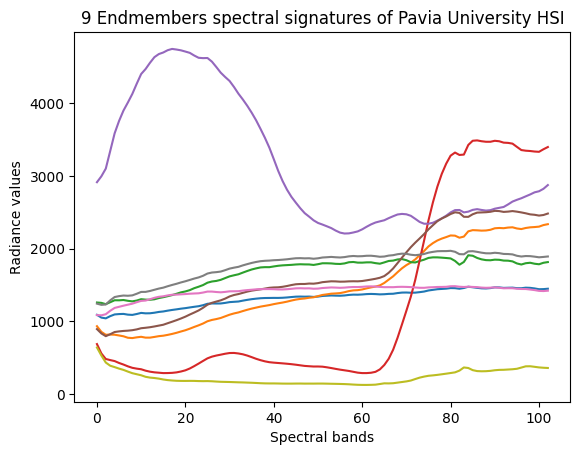

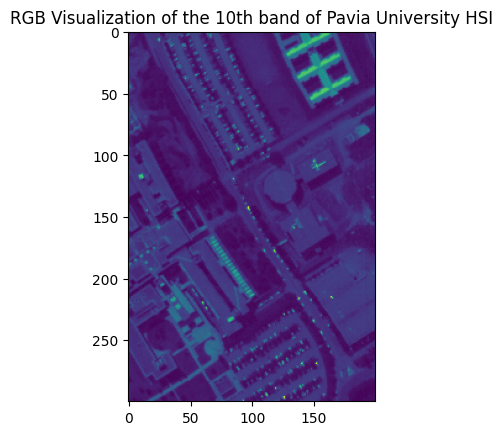

In [2]:
import scipy.io as sio
import numpy as np
import scipy.optimize 
import matplotlib.pyplot as plt
Pavia = sio.loadmat('PaviaU_cube.mat')
HSI = Pavia['X'] #Pavia HSI : 300x200x103

ends = sio.loadmat('PaviaU_endmembers.mat') # Endmember's matrix: 103x9
endmembers = ends['endmembers']
fig = plt.figure()
plt.plot(endmembers)
plt.ylabel('Radiance values')
plt.xlabel('Spectral bands')
plt.title('9 Endmembers spectral signatures of Pavia University HSI')
plt.show()

#Perform unmixing for the pixels corresponding to nonzero labels
ground_truth= sio.loadmat('PaviaU_ground_truth.mat')
labels=ground_truth['y']

fig = plt.figure()
plt.imshow(HSI[:,:,10])
plt.title('RGB Visualization of the 10th band of Pavia University HSI')
plt.show()
# For the non-negative least squares  unmixing algorithm  you can use the nnls function, see the following link:
#https://docs.scipy.org/doc/scipy-0.18.1/reference/generated/scipy.optimize.nnls.html#scipy.optimize.nnls
# ..............
#
#..................

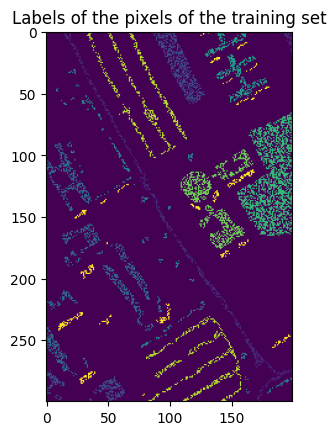

In [3]:
# Trainining set for classification 
Pavia_labels = sio.loadmat('classification_labels_Pavia.mat')
Training_Set = (np.reshape(Pavia_labels['training_set'],(200,300))).T
Test_Set = (np.reshape(Pavia_labels['test_set'],(200,300))).T
Operational_Set = (np.reshape(Pavia_labels['operational_set'],(200,300))).T

fig = plt.figure()
plt.imshow(Training_Set)
plt.title('Labels of the pixels of the training set')
plt.show()

In [4]:
from scipy.optimize import nnls, minimize
from sklearn.linear_model import Lasso

# Τα 9 υλικά (endmembers) με τη σειρά του πίνακα της εκφώνησης
materials = [
    'Water', 'Trees', 'Asphalt', 'Self-Blocking Bricks', 
    'Bitumen', 'Tiles', 'Shadows', 'Meadows', 'Bare Soil'
]

# Κρατάμε ΜΟΝΟ τα pixels με μη μηδενική ετικέτα (labels != 0)
mask = (labels != 0)
Y = HSI[mask].T  # Διαστάσεις: (103, N_nonzero) - κάθε στήλη είναι ένα pixel y_i
X = endmembers   # Διαστάσεις: (103, 9)
N_pixels = Y.shape[1]

print(f"Συνολικά μη μηδενικά pixels προς επεξεργασία: {N_pixels}")

# Συνάρτηση υπολογισμού του μέσου Reconstruction Error: mean(||y_i - X*theta_i||^2)
def compute_recon_error(Y_true, X_mat, Theta):
    diff = Y_true - (X_mat @ Theta)
    return np.mean(np.sum(diff**2, axis=0))

# Συνάρτηση σχεδιασμού των 9 Abundance Maps σε πλέγμα 3x3
def plot_abundance_maps(Theta, method_name):
    maps = np.zeros((300, 200, 9))
    maps[mask] = Theta.T  # Τοποθετούμε τα αποτελέσματα πίσω στις σωστές συντεταγμένες
    
    fig, axes = plt.subplots(3, 3, figsize=(10, 12))
    fig.suptitle(f'Abundance Maps - {method_name}', fontsize=14, y=0.98)
    
    for idx, ax in enumerate(axes.flat):
        im = ax.imshow(maps[:, :, idx], cmap='viridis')
        ax.set_title(f'{idx+1}. {materials[idx]}')
        ax.axis('off')
        fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
        
    plt.tight_layout()
    plt.show()

Συνολικά μη μηδενικά pixels προς επεξεργασία: 12829


In [5]:
import warnings
warnings.filterwarnings('ignore')

# Προ-υπολογισμός πινάκων για ταχύτητα
XtX = X.T @ X
XtX_inv = np.linalg.inv(XtX)
XtY = X.T @ Y
ones = np.ones((9, 1))

# (a) Απλά Ελάχιστα Τετράγωνα (Least Squares) 
Theta_LS = XtX_inv @ XtY
err_LS = compute_recon_error(Y, X, Theta_LS)
print(f"(a) Least Squares - Reconstruction Error: {err_LS:.2f}")

# (b) Least Squares με περιορισμό sum-to-one (SCLS) 
# Κλειστός τύπος μέσω πολλαπλασιαστών Lagrange
num = (ones.T @ Theta_LS) - 1
den = ones.T @ XtX_inv @ ones
Theta_SCLS = Theta_LS - (XtX_inv @ ones) @ (num / den)
err_SCLS = compute_recon_error(Y, X, Theta_SCLS)
print(f"(b) LS (Sum-to-One) - Reconstruction Error: {err_SCLS:.2f}")

# (c) Non-Negative Least Squares (NNLS)
Theta_NNLS = np.zeros((9, N_pixels))
for i in range(N_pixels):
    Theta_NNLS[:, i], _ = nnls(X, Y[:, i])
err_NNLS = compute_recon_error(Y, X, Theta_NNLS)
print(f"(c) NNLS - Reconstruction Error: {err_NNLS:.2f}")

# (d) Fully Constrained LS (Non-negativity + Sum-to-One) 
Theta_FCLS = np.zeros((9, N_pixels))
bounds = [(0, None)] * 9
constraints = {'type': 'eq', 'fun': lambda t: np.sum(t) - 1.0}

for i in range(N_pixels):
    xty_i = XtY[:, i]
    # Συνάρτηση κόστους και παράγωγος (Jacobian) για γρήγορη σύγκλιση
    fun = lambda t: t @ XtX @ t - 2 * (xty_i @ t)
    jac = lambda t: 2 * (XtX @ t - xty_i)
    
    # Αρχική τιμή: κανονικοποιημένη λύση του NNLS
    t0 = Theta_NNLS[:, i]
    t0 = t0 / np.sum(t0) if np.sum(t0) > 0 else np.ones(9) / 9.0
    
    res = minimize(fun, t0, method='SLSQP', jac=jac, bounds=bounds, constraints=constraints)
    Theta_FCLS[:, i] = res.x

err_FCLS = compute_recon_error(Y, X, Theta_FCLS)
print(f"(d) FCLS (NN + Sum-to-One) - Reconstruction Error: {err_FCLS:.2f}")

# (e) LASSO (l1 norm minimization) 
# Το alpha ρυθμίζει την αραιότητα (επειδή οι τιμές του HSI είναι ~1000-4000, δοκιμάζουμε alpha=100)
lasso = Lasso(alpha=100.0, fit_intercept=False, max_iter=5000)
lasso.fit(X, Y)
Theta_LASSO = lasso.coef_.T  # Διαστάσεις: (9, N_pixels)
err_LASSO = compute_recon_error(Y, X, Theta_LASSO)
print(f"(e) LASSO - Reconstruction Error: {err_LASSO:.2f}")

(a) Least Squares - Reconstruction Error: 118783.18
(b) LS (Sum-to-One) - Reconstruction Error: 160049.93
(c) NNLS - Reconstruction Error: 569339.29
(d) FCLS (NN + Sum-to-One) - Reconstruction Error: 5039602.32
(e) LASSO - Reconstruction Error: 167601.39


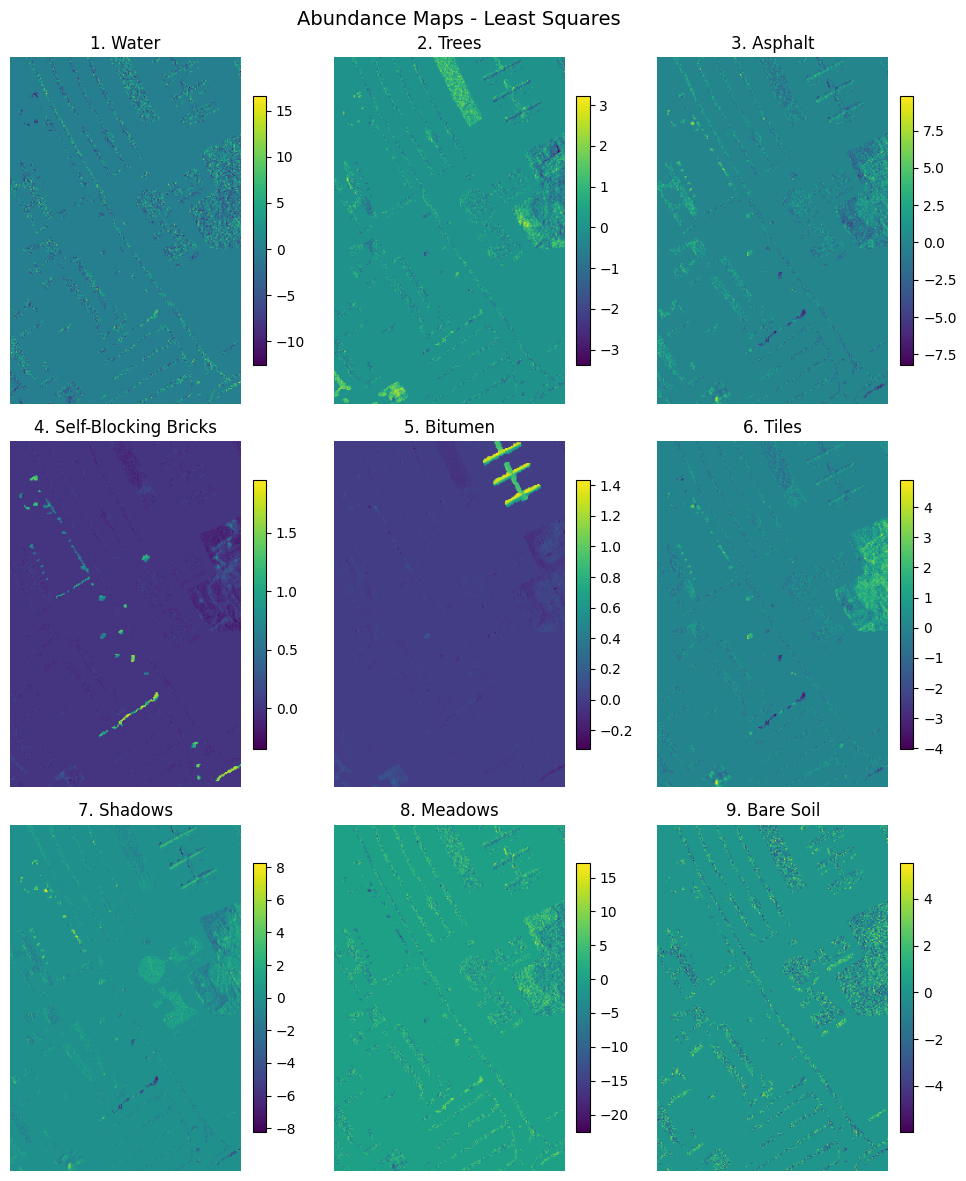

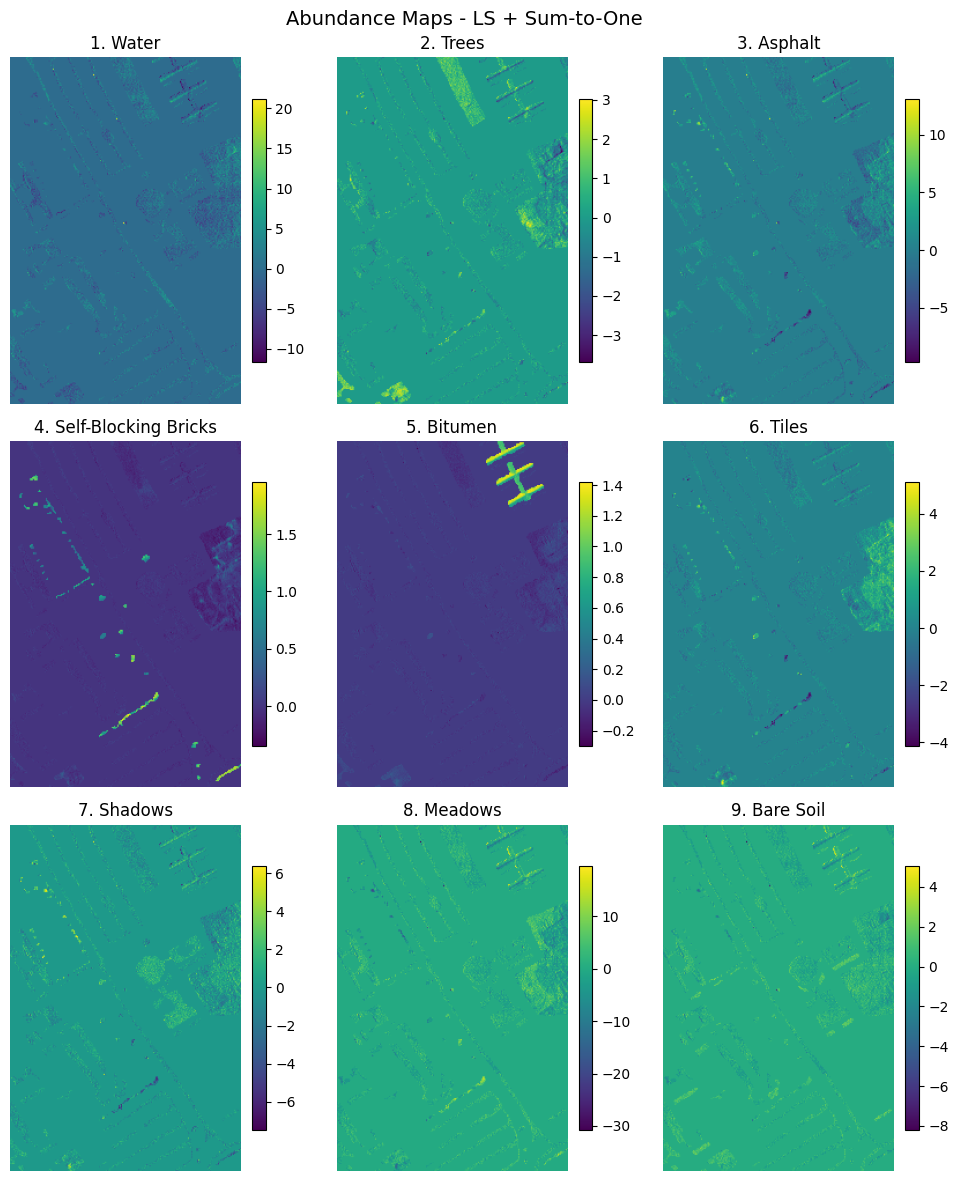

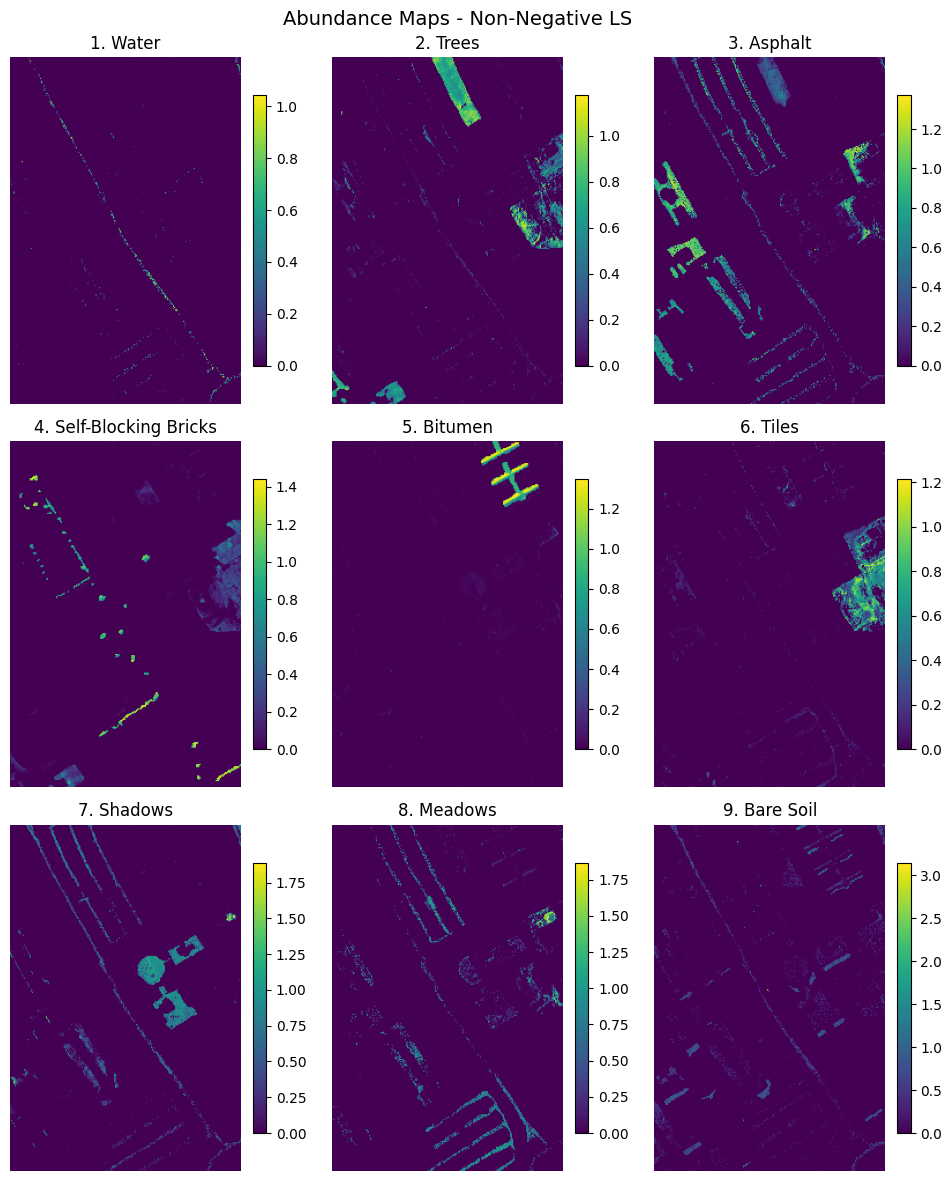

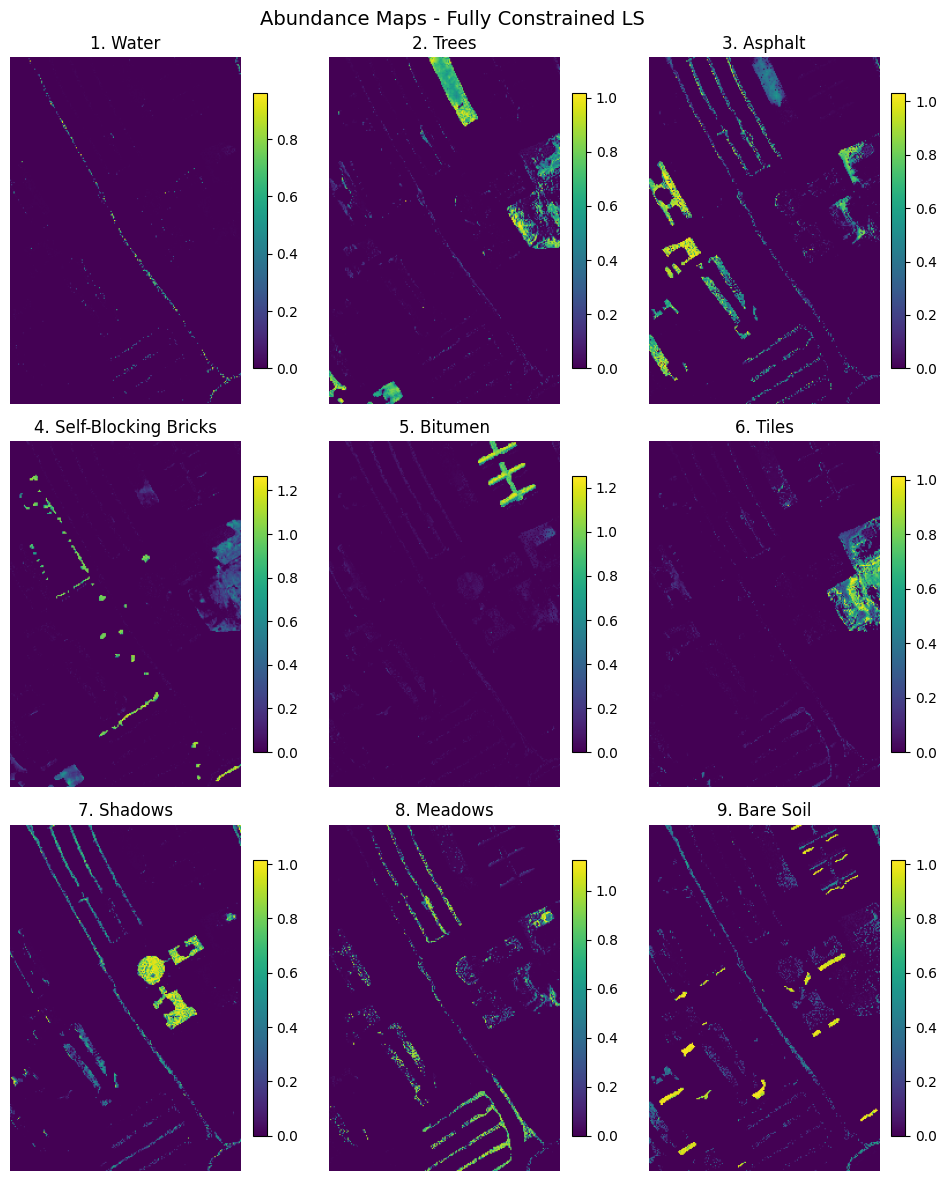

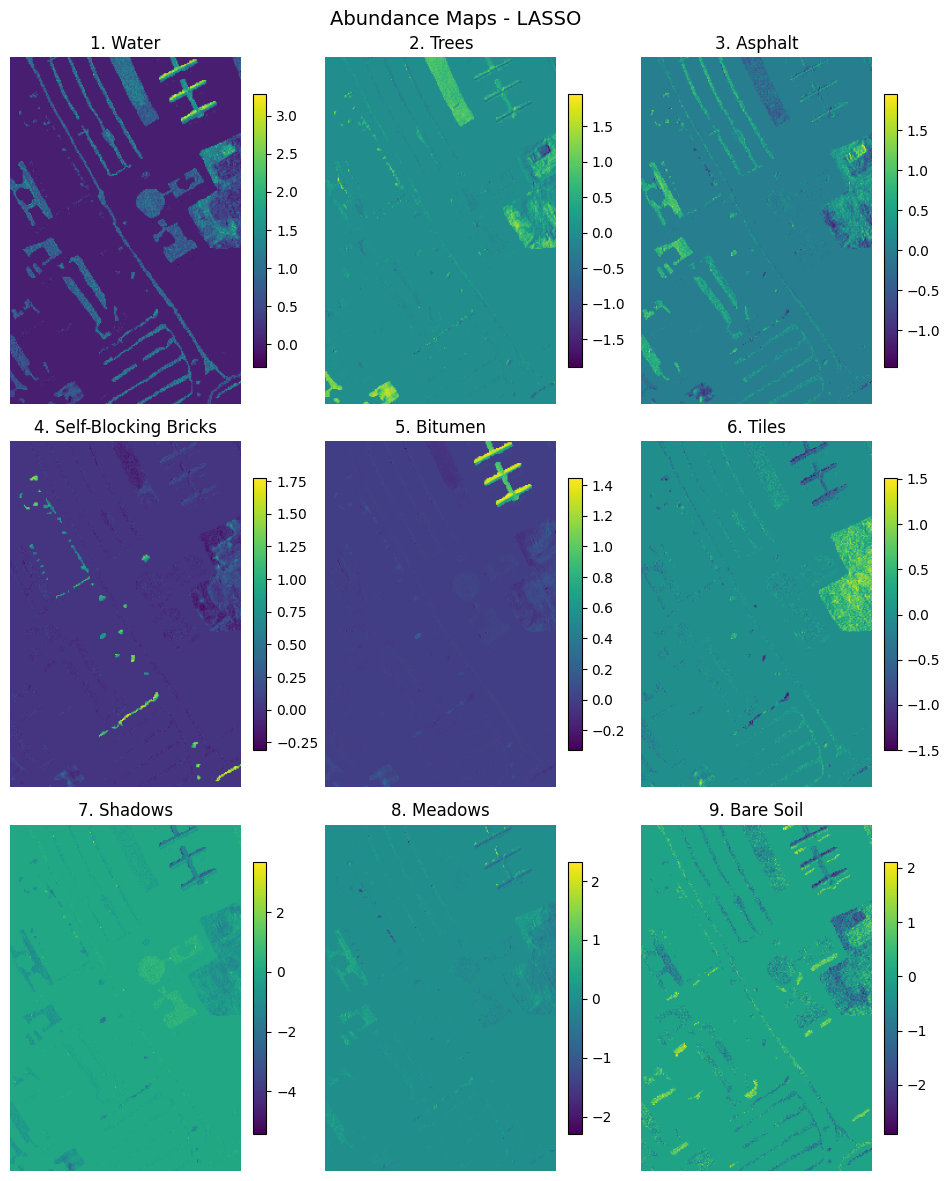

In [6]:
plot_abundance_maps(Theta_LS, "Least Squares")
plot_abundance_maps(Theta_SCLS, "LS + Sum-to-One")
plot_abundance_maps(Theta_NNLS, "Non-Negative LS")
plot_abundance_maps(Theta_FCLS, "Fully Constrained LS")
plot_abundance_maps(Theta_LASSO, "LASSO")

### Part 1 (B): Comparison and Commentary on Spectral Unmixing Methods

#### Reconstruction Error Summary
| Method | Constraints | Mean Reconstruction Error |
| :--- | :--- | :---: |
| **(a) Least Squares (LS)** | None | 118,783.18 |
| **(b) LS + Sum-to-One (SCLS)** | $\sum \theta_i = 1$ | 160,049.93 |
| **(c) Non-Negative LS (NNLS)** | $\theta_i \ge 0$ | 569,339.29 |
| **(d) Fully Constrained LS (FCLS)** | $\theta_i \ge 0$ and $\sum \theta_i = 1$ | 5,039,602.32 |
| **(e) LASSO** | Sparsity ($\ell_1$-norm regularization) | 167,601.39 |

#### Observations & Comparison
There is a clear **trade-off between mathematical reconstruction error and physical interpretability** of the abundance maps:

1. **Reconstruction Error vs. Constraints:** As we impose stricter constraints on the abundance vector $\theta$, the feasible solution space shrinks, inevitably increasing the reconstruction error. Consequently, unconstrained **Least Squares (LS)** achieves the lowest error (118,783.18), while **FCLS** yields the highest (5,039,602.32).
2. **Unconstrained LS & Sum-to-One LS:** Although both methods produce low reconstruction errors, their abundance maps are noisy and physically meaningless. Because they allow negative values and values far exceeding 1 (e.g., ranging from -20 to +15 in *Water* and *Meadows*), the estimated abundances cannot be interpreted as material percentages.
3. **Non-Negative LS (NNLS):** Enforcing the non-negativity constraint ($\theta_i \ge 0$) dramatically improves the visual quality of the abundance maps. Distinct spatial structures—such as buildings, roads (*Asphalt*), *Trees*, *Bitumen*, and *Shadows*—become clearly visible and align closely with the classes in `PaviaU_ground_truth.mat`, despite the higher reconstruction error (569,339.29).
4. **Fully Constrained LS (FCLS):** Adding both non-negativity and sum-to-one constraints produces clean, physically valid percentage maps, but causes a sharp spike in reconstruction error (5,039,602.32). In real hyperspectral scenes, illumination variations (e.g., shadows, surface topography) scale pixel brightness. Forcing $\sum \theta_i = 1$ prevents the model from absorbing these brightness variations.
5. **LASSO:** By promoting sparsity via $\ell_1$ regularization, LASSO sets most irrelevant endmember weights to zero (reflecting the fact that each pixel typically consists of only a few materials) while maintaining a low reconstruction error (167,601.39). However, without a non-negativity constraint, it can still produce some negative coefficients.

In [7]:
# Part 2: Classification - Data Preparation 
from sklearn.base import BaseEstimator, ClassifierMixin
from sklearn.model_selection import cross_val_score
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.discriminant_analysis import QuadraticDiscriminantAnalysis
from sklearn.metrics import confusion_matrix
import seaborn as sns

# Extract non-zero pixels for Training, Test, and Operational sets
train_mask = (Training_Set != 0)
test_mask = (Test_Set != 0)
oper_mask = (Operational_Set != 0)

X_train = HSI[train_mask]
y_train = Training_Set[train_mask]

X_test = HSI[test_mask]
y_test = Test_Set[test_mask]

X_oper = HSI[oper_mask]
y_oper = Operational_Set[oper_mask]

print(f"Training set: {X_train.shape[0]} pixels, {X_train.shape[1]} bands")
print(f"Test set: {X_test.shape[0]} pixels")
print(f"Operational set: {X_oper.shape[0]} pixels")

Training set: 6415 pixels, 103 bands
Test set: 3207 pixels
Operational set: 3207 pixels


In [8]:
# Custom Implementation of Minimum Euclidean Distance Classifier 
class MinimumEuclideanDistanceClassifier(BaseEstimator, ClassifierMixin):
    def fit(self, X, y):
        self.classes_ = np.unique(y)
        # Compute the mean vector (centroid) for each class
        self.means_ = np.array([X[y == c].mean(axis=0) for c in self.classes_])
        return self

    def predict(self, X):
        # Compute Euclidean distance from each sample to every class centroid
        # Using broadcasting: (N_samples, 1, N_features) - (1, N_classes, N_features)
        distances = np.linalg.norm(X[:, np.newaxis, :] - self.means_[np.newaxis, :, :], axis=2)
        # Assign each sample to the class with the minimum distance
        nearest_class_idx = np.argmin(distances, axis=1)
        return self.classes_[nearest_class_idx]

=== 10-Fold Cross-Validation & Test Set Results ===

[Naive Bayes]
  10-Fold CV Validation Error : 0.3553 (+/- 0.0568)
  Test Set Success Rate       : 66.01%

[Min Euclidean Distance]
  10-Fold CV Validation Error : 0.4653 (+/- 0.1054)
  Test Set Success Rate       : 55.78%

[k-NN (k=5)]
  10-Fold CV Validation Error : 0.1520 (+/- 0.0541)
  Test Set Success Rate       : 88.65%

[Bayesian Classifier (QDA)]
  10-Fold CV Validation Error : 0.1439 (+/- 0.0296)
  Test Set Success Rate       : 88.43%



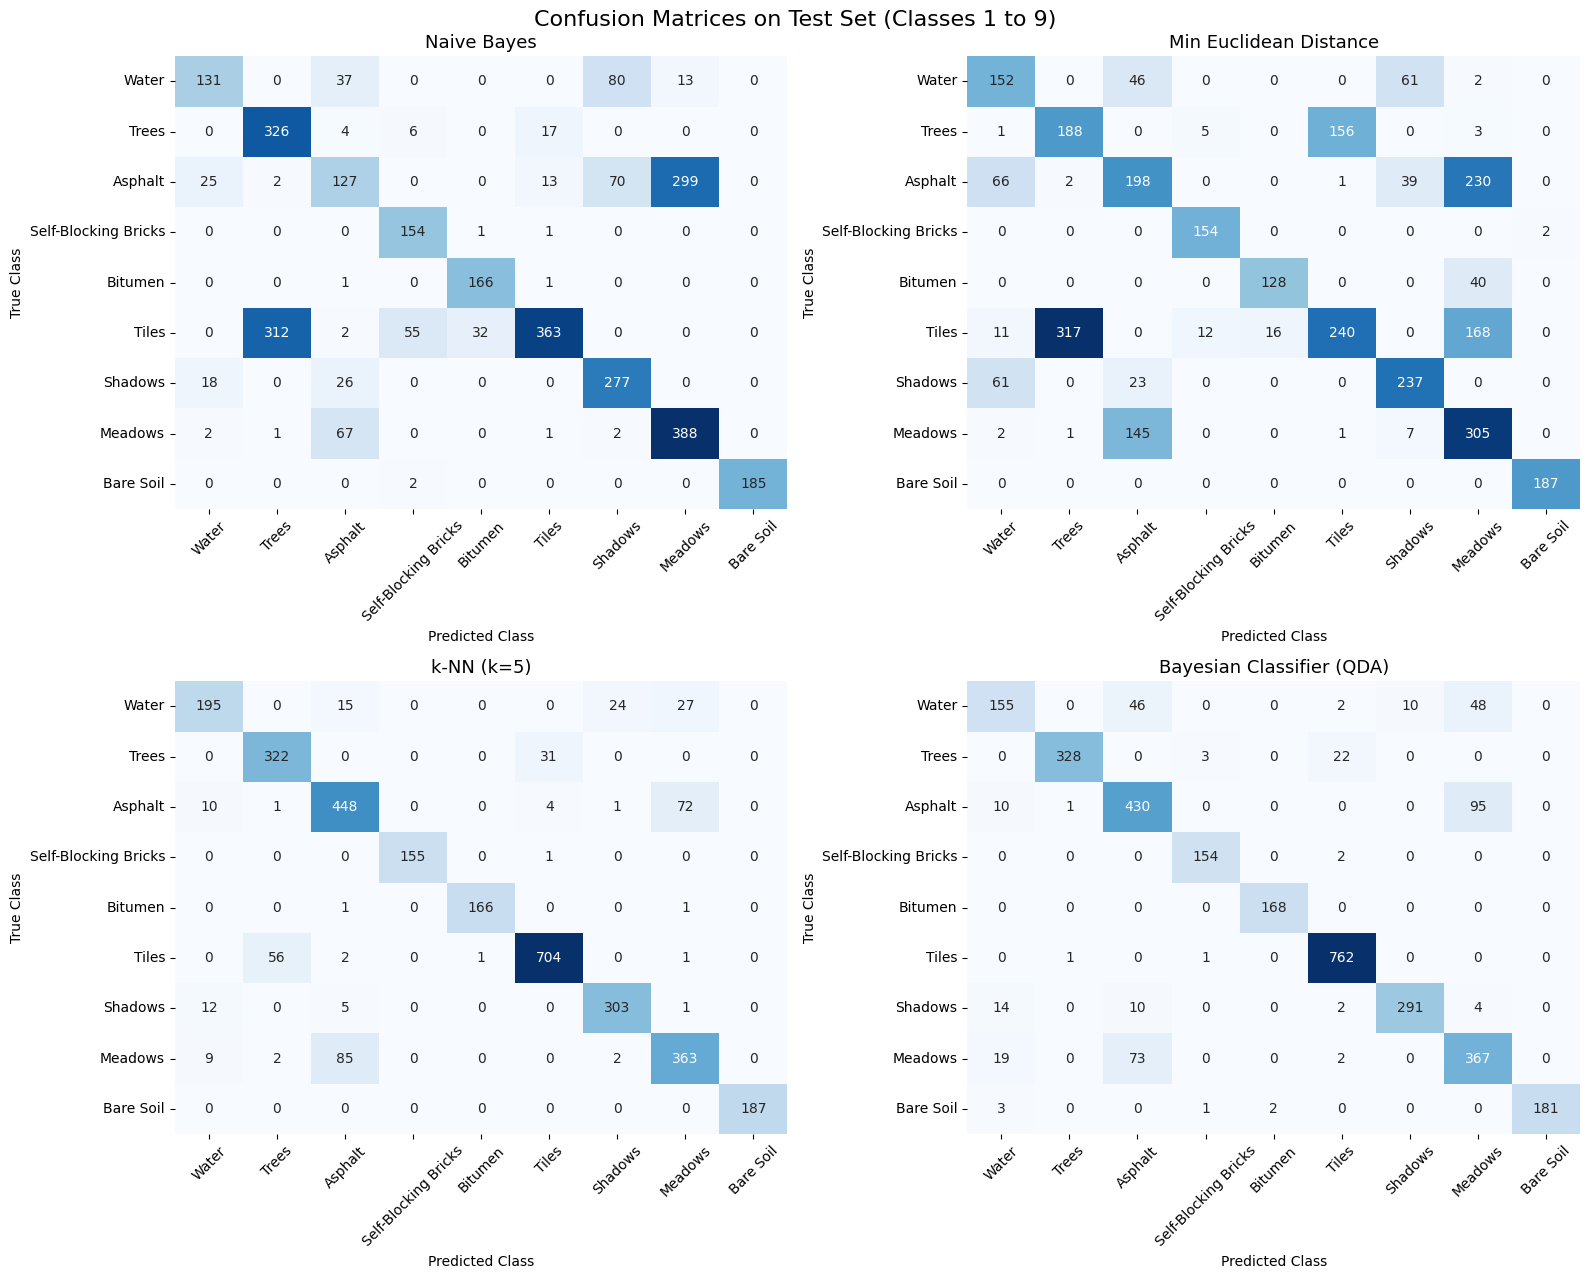

In [9]:
# Part 2 (A): 10-Fold Cross-Validation & Test Set Evaluation 
classifiers = {
    "Naive Bayes": GaussianNB(),
    "Min Euclidean Distance": MinimumEuclideanDistanceClassifier(),
    "k-NN (k=5)": KNeighborsClassifier(n_neighbors=5),
    "Bayesian Classifier (QDA)": QuadraticDiscriminantAnalysis(reg_param=1e-4)
}

conf_matrices = {}

print("=== 10-Fold Cross-Validation & Test Set Results ===\n")

for name, clf in classifiers.items():
    # (i) 10-fold Cross-Validation on the Training Set
    cv_scores = cross_val_score(clf, X_train, y_train, cv=10, scoring='accuracy')
    cv_errors = 1.0 - cv_scores
    mean_err = np.mean(cv_errors)
    std_err = np.std(cv_errors)
    
    # (ii) Train on the WHOLE Training Set and evaluate on the Test Set
    clf.fit(X_train, y_train)
    y_pred = clf.predict(X_test)
    
    # Confusion Matrix (9x9)
    cm = confusion_matrix(y_test, y_pred, labels=np.arange(1, 10))
    conf_matrices[name] = cm
    
    # Success Rate = sum of diagonal / sum of all elements
    success_rate = np.trace(cm) / np.sum(cm)
    
    print(f"[{name}]")
    print(f"  10-Fold CV Validation Error : {mean_err:.4f} (+/- {std_err:.4f})")
    print(f"  Test Set Success Rate       : {success_rate*100:.2f}%\n")

# Plot all four 9x9 Confusion Matrices in a 2x2 grid
fig, axes = plt.subplots(2, 2, figsize=(16, 13))
fig.suptitle('Confusion Matrices on Test Set (Classes 1 to 9)', fontsize=16, y=0.98)

for ax, (name, cm) in zip(axes.flat, conf_matrices.items()):
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=ax,
                xticklabels=materials, yticklabels=materials, cbar=False)
    ax.set_title(name, fontsize=13)
    ax.set_xlabel('Predicted Class')
    ax.set_ylabel('True Class')
    ax.tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

### Part 2 (B): Comparison and Commentary on Classifiers

#### Performance Summary
| Classifier | 10-Fold CV Error (Mean ± Std) | Test Set Success Rate |
| :--- | :---: | :---: |
| **Naive Bayes** | 0.3553 ± 0.0568 | 66.01% |
| **Min Euclidean Distance** | 0.4653 ± 0.1054 | 55.78% |
| **k-NN (k=5)** | 0.1520 ± 0.0541 | **88.65%** |
| **Bayesian Classifier (QDA)** | **0.1439 ± 0.0296** | 88.43% |

#### Observations & Confusion Matrix Analysis
1. **Overall Performance:** **k-NN (k=5)** and the **Bayesian Classifier (QDA)** achieve the highest accuracy (~88.5%) and the lowest cross-validation errors, with QDA also showing the lowest variance (±0.0296), indicating strong stability across folds. In contrast, **Minimum Euclidean Distance** (55.78%) and **Naive Bayes** (66.01%) perform significantly worse.
2. **Why QDA and k-NN Outperform Naive Bayes and Min Distance:**
   * **Minimum Euclidean Distance** only uses class centroids and assumes spherical, equal-variance classes, ignoring feature correlations across the 103 spectral bands.
   * **Naive Bayes** assumes conditional independence between spectral bands. In hyperspectral imaging, adjacent spectral bands are heavily correlated, so this assumption breaks down.
   * **QDA** models the full covariance matrix for each class, capturing band correlations and class shapes, while **k-NN** is non-parametric and adapts flexibly to complex decision boundaries.
3. **Key Misclassifications (Non-Diagonal Entries):**
   * **Tiles vs. Trees:** Both *Naive Bayes* (312 *Tiles* misclassified as *Trees*) and *Min Distance* (317 *Tiles* as *Trees*, 154 *Trees* as *Tiles*) struggle heavily to separate these classes. *QDA* resolves this almost completely (762 *Tiles* correctly classified), and *k-NN* reduces it drastically (56 misclassified).
   * **Asphalt vs. Meadows:** This is the most persistent confusion across all four models. Even the best classifiers show noticeable off-diagonal entries here (*k-NN*: 72 *Asphalt* as *Meadows* and 85 *Meadows* as *Asphalt*; *QDA*: 95 *Asphalt* as *Meadows* and 73 *Meadows* as *Asphalt*), while *Naive Bayes* (299) and *Min Distance* (230) fail severely.
   * **Water vs. Shadows & Asphalt:** *Water* is frequently confused with *Shadows* and *Asphalt* across models (especially in *Naive Bayes* and *Min Distance*), because all three materials exhibit low reflectance across many spectral bands.
   * **Well-Separated Classes:** *Self-Blocking Bricks*, *Bitumen*, and *Bare Soil* are consistently separated with very high accuracy across almost all classifiers.

---

### Part 3: Combination (Correlation Between Spectral Unmixing and Classification)

There is a strong correlation between the sub-pixel mixing observed in **Part 1 (Spectral Unmixing)** and the classification errors seen in **Part 2 (Classification)**:

1. **Mixed Pixels Drive Classification Errors:** In the abundance maps of **NNLS** and **FCLS**, materials that appear spatially intermingled or share similar spectral responses (such as *Asphalt* with *Meadows* along road edges, or *Water* with *Shadows* due to low radiance) are the exact same class pairs that produce the largest off-diagonal errors in the confusion matrices. When a pixel is heavily mixed, forcing a classifier to assign it to a single hard label inevitably increases the error rate.
2. **Pure/Distinct Materials Are Easily Classified:** Conversely, materials whose abundance maps are sharply localized and cleanly separated from other endmembers—such as *Bitumen* (the distinct H-shaped roof structure), *Self-Blocking Bricks*, and *Bare Soil*—correspond directly to the classes with near-perfect diagonal entries in the confusion matrices.
3. **Complementary Nature:** While **classification** provides a discrete label map useful for high-level scene segmentation, **spectral unmixing** explains *why* certain regions are ambiguous by revealing the underlying sub-pixel material composition. Combining both approaches allows us to identify which misclassified pixels are simply mixed boundary pixels rather than true model failures.